# Predicción de mora en préstamos — Mutual Nacional de Funcionarios del MSP y BS
**Proyecto Final M7 · Héctor Villalba**

**Problema:** la mutual otorga ~1.000 préstamos por mes. Una parte termina con más de 60 días de atraso, lo que genera previsiones y pérdidas.
**Objetivo:** estimar, para cada préstamo, la probabilidad de que llegue a **más de 60 días de atraso**, para priorizar la cobranza preventiva.
**Métrica principal:** PR-AUC (Average Precision), porque la clase positiva es minoritaria (~6%) y lo que interesa es encontrar a los morosos; ROC-AUC como métrica complementaria.

> Nota: para la programación de este notebook se usó un asistente de IA (Claude). Los datos, el diseño del problema y las conclusiones son del autor.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
SEED = 42

## 1. Construcción del dataset

Fuentes (reportes del sistema de la mutual, corte 30/09/2026):
- **PlanillaPrevisiones**: una fila por préstamo vigente, con datos del otorgamiento y días vencidos.
- **DetalleAtrasoRegional**: regional y zona de cada socio (se cruza por cédula).

Decisiones clave:
- **Target** `mora_60` = 1 si el préstamo tiene **más de 60 días vencidos** al corte.
- **Solo variables conocidas al otorgar el préstamo** (monto, plazo, tasa, cuota, tipo, oficial, regional). Se excluyen saldos, intereses, fecha de último pago, categoría y saldo de aportes para evitar *data leakage*.
- **Ventana**: préstamos otorgados entre abril 2025 y marzo 2026 y todavía dentro de su plazo. Los préstamos más viejos que siguen vigentes están sesgados (los buenos pagadores ya terminaron de pagar: sesgo de supervivencia), y los de menos de 6 meses todavía no tuvieron tiempo de caer en mora.
- **Fuga de datos detectada y corregida**: `DetalleAtrasoRegional` solo lista socios **activos** hoy. Los préstamos de socios que no aparecen (excluidos, en cobro judicial, fallecidos) tenían 31,6% de mora contra ~6% del resto: su ausencia es una consecuencia de la mora, no una causa. En una primera versión, "regional desconocida" era la variable más importante del modelo, lo que inflaba artificialmente las métricas. Se excluyen esos préstamos; la población queda en socios activos, que es la misma a la que se le otorgan préstamos nuevos.
- `meses_en_cartera` controla el tiempo de exposición; en producción se fija en 12 (probabilidad de mora a 12 meses).
- **Anonimización**: se eliminan cédula, nombre y número de préstamo; los oficiales se reemplazan por códigos.

Esta celda solo se ejecuta si están los reportes originales (no se suben por privacidad). Si no están, se usa `datos_muestra.csv`.

In [2]:
RAW = Path("raw")
CORTE = pd.Timestamp("2026-09-30")
if (RAW / "PlanillaPrevisiones_20260930.xlsx").exists():
    p = pd.read_excel(RAW / "PlanillaPrevisiones_20260930.xlsx", sheet_name="Planilla")
    p.columns = [c.strip() for c in p.columns]
    p = p[p["Nro. Préstamo"].notna()].copy()            # se descarta la fila de TOTALES
    p["fecha_gen"] = pd.to_datetime(p["Fecha Generación"])
    p = p.sort_values(["Cédula", "fecha_gen"])
    p["prestamos_vigentes_previos"] = p.groupby("Cédula").cumcount()
    reg = (pd.read_excel(RAW / "DetalleAtrasoRegional.xls", engine="xlrd")
             [["Cédula", "Regional", "Zona"]].drop_duplicates("Cédula"))
    d = p.merge(reg, on="Cédula", how="inner")            # solo socios activos (ver fuga de datos arriba)
    d["meses_en_cartera"] = ((CORTE - d["fecha_gen"]).dt.days / 30.44).round(1)
    fin_plazo = d["fecha_gen"] + pd.to_timedelta(d["Plazo"] * 30.44, unit="D")
    d = d[(d["fecha_gen"] >= "2025-04-01") & (d["fecha_gen"] <= "2026-03-31") & (fin_plazo > CORTE)].copy()
    codigos = {o: f"OF_{i:03d}" for i, o in enumerate(d["Oficial"].fillna("SIN OFICIAL").value_counts().index, 1)}
    df = pd.DataFrame({
        "fecha_otorgamiento": d["fecha_gen"].dt.date,
        "tipo_prestamo": d["Tipo Préstamo"].str.replace("PRESTAMO ", "", regex=False),
        "monto_otorgado": d["Monto Otorgado (Consesión)"],
        "plazo_meses": d["Plazo"],
        "tasa_mensual": d["Tasa Mensual"],
        "cuota": d["Cuota"],
        "nro_socio": d["Socio"],
        "prestamos_vigentes_previos": d["prestamos_vigentes_previos"],
        "regional": d["Regional"],
        "zona": d["Zona"],
        "oficial": d["Oficial"].fillna("SIN OFICIAL").map(codigos),
        "meses_en_cartera": d["meses_en_cartera"],
        "mora_60": (d["Dias Vencidos"] > 60).astype(int),
    })
    df.to_csv("dataset_mora.csv", index=False)
    print("Dataset construido desde los reportes originales.")

Dataset construido desde los reportes originales.


## 2. Carga de datos

In [3]:
archivo = "dataset_mora.csv" if Path("dataset_mora.csv").exists() else "datos_muestra.csv"
df = pd.read_csv(archivo)
print(f"Archivo: {archivo} | {df.shape[0]:,} préstamos | tasa de mora >60 días: {df.mora_60.mean():.2%}")
df.head()

Archivo: dataset_mora.csv | 7,755 préstamos | tasa de mora >60 días: 5.88%


,fecha_otorgamiento,tipo_prestamo,monto_otorgado,plazo_meses,tasa_mensual,cuota,nro_socio,prestamos_vigentes_previos,regional,zona,oficial,meses_en_cartera,mora_60
0,2025-12-17,EXTRAORDINARIO,2732643,18.0,2.0,206465,1498,0,XV RS - PDTE. HAYES,INTERIOR,OF_040,9.4,0
1,2026-03-10,EXTRAORDINARIO,9000000,24.0,2.0,555000,1498,1,XV RS - PDTE. HAYES,INTERIOR,OF_040,6.7,0
2,2026-03-18,EXTRAORDINARIO,5000000,24.0,2.0,308333,29604,0,NIVEL CENTRAL - GRAN ASUNCION,CAPITAL,OF_001,6.4,0
3,2026-01-23,ORDINARIO,3000000,12.0,1.8,304000,7070,0,NIVEL CENTRAL - GRAN ASUNCION,CAPITAL,OF_001,8.2,0
4,2026-02-25,ORDINARIO,5500000,24.0,2.0,339166,852,0,NIVEL CENTRAL - GRAN ASUNCION,CAPITAL,OF_002,7.1,0


## 3. Análisis exploratorio

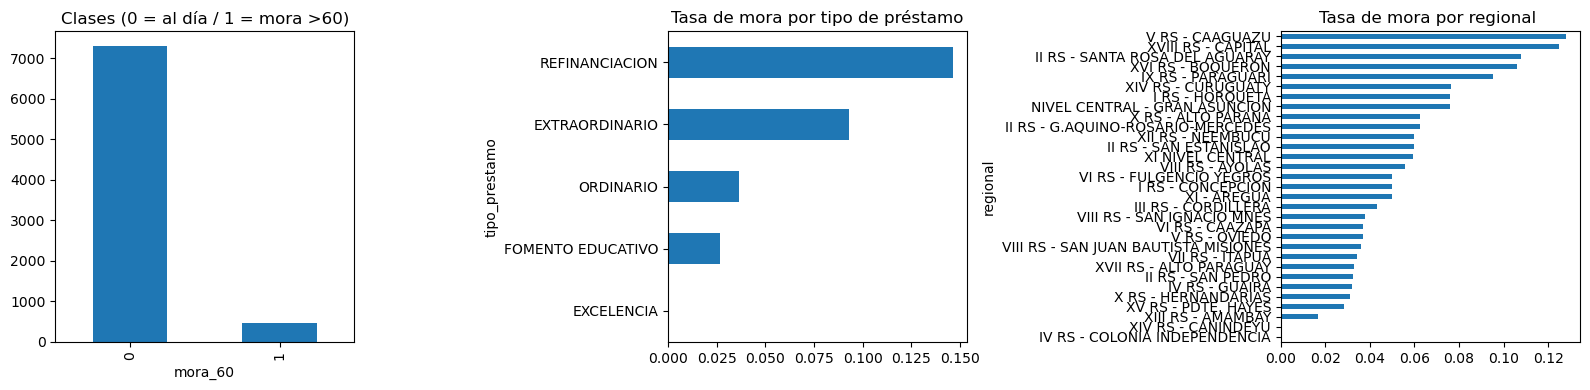

,prestamos,tasa_mora
meses_en_cartera,,
"(5, 8]",3171,0.026805
"(8, 11]",2535,0.046943
"(11, 14]",1251,0.069544
"(14, 19]",798,0.206767


In [4]:
n_min = 30 if len(df) > 1000 else 3   # con la muestra de 100 filas se baja el mínimo por grupo
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.mora_60.value_counts().plot.bar(ax=ax[0], title="Clases (0 = al día / 1 = mora >60)")
(df.groupby("tipo_prestamo").mora_60.agg(["mean", "size"]).query("size >= @n_min")["mean"]
   .sort_values().plot.barh(ax=ax[1], title="Tasa de mora por tipo de préstamo"))
(df.groupby("regional").mora_60.agg(["mean", "size"]).query("size >= @n_min")["mean"]
   .sort_values().plot.barh(ax=ax[2], title="Tasa de mora por regional "))
plt.tight_layout(); plt.show()
df.groupby(pd.cut(df.meses_en_cartera, [5, 8, 11, 14, 19])).mora_60.agg(["size", "mean"]).rename(columns={"size": "prestamos", "mean": "tasa_mora"})

La tasa de mora crece con los meses en cartera (más tiempo de exposición). Por eso `meses_en_cartera` entra como variable de control.

## 4. Separación train / test

In [5]:
df["ratio_cuota_monto"] = df.cuota / df.monto_otorgado
NUM = ["monto_otorgado", "plazo_meses", "tasa_mensual", "cuota", "ratio_cuota_monto",
       "nro_socio", "prestamos_vigentes_previos", "meses_en_cartera"]
CAT = ["tipo_prestamo", "regional", "zona", "oficial"]
X, y = df[NUM + CAT], df["mora_60"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {len(X_train):,} ({y_train.mean():.2%} mora) | Test: {len(X_test):,} ({y_test.mean():.2%} mora)")

Train: 6,204 (5.88% mora) | Test: 1,551 (5.87% mora)


Split aleatorio estratificado. Se evaluó un split temporal, pero las cohortes recientes tienen menos meses de exposición que las antiguas, y el modelo tendría que extrapolar `meses_en_cartera` fuera del rango de entrenamiento. Queda como mejora cuando haya historial con resultado a horizonte fijo.

## 5. Preprocesamiento: ColumnTransformer + Pipeline

In [6]:
preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), CAT),
])
modelos = {
    "Regresión logística (baseline)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, class_weight="balanced",
                                                        random_state=SEED),
}

## 6. Entrenamiento y validación cruzada (5 folds, solo sobre train)

In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
filas = []
for nombre, m in modelos.items():
    pipe = Pipeline([("pre", preprocesador), ("modelo", m)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    filas.append({"modelo": nombre, "ROC-AUC (CV)": r["test_roc_auc"].mean(), "PR-AUC (CV)": r["test_average_precision"].mean()})
resultados_cv = pd.DataFrame(filas).set_index("modelo").round(3)
resultados_cv

,ROC-AUC (CV),PR-AUC (CV)
modelo,,
Regresión logística (baseline),0.790,0.258
Random Forest,0.786,0.256
Gradient Boosting,0.770,0.225


In [8]:
mejor = resultados_cv["PR-AUC (CV)"].idxmax()
print("Modelo elegido por PR-AUC en validación cruzada:", mejor)
modelo = Pipeline([("pre", preprocesador), ("modelo", modelos[mejor])]).fit(X_train, y_train)
baseline = Pipeline([("pre", preprocesador), ("modelo", modelos["Regresión logística (baseline)"])]).fit(X_train, y_train)

Modelo elegido por PR-AUC en validación cruzada: Regresión logística (baseline)


## 7. Evaluación sobre test

Regresión logística (baseline): ROC-AUC = 0.808 | PR-AUC = 0.241
Baseline logístico: ROC-AUC = 0.808 | PR-AUC = 0.241
Clasificador aleatorio: PR-AUC = 0.059 (igual a la tasa de mora)


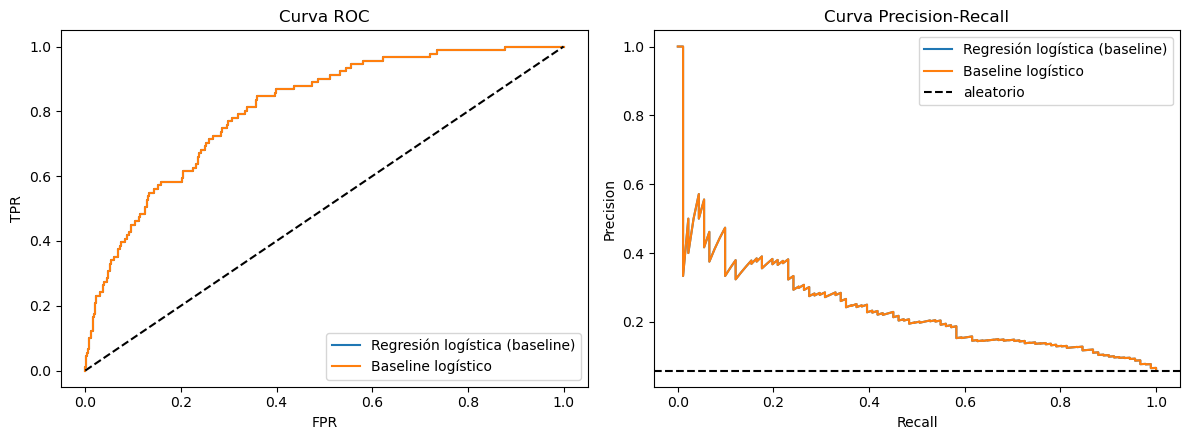

In [9]:
p_test = modelo.predict_proba(X_test)[:, 1]
p_base = baseline.predict_proba(X_test)[:, 1]
print(f"{mejor}: ROC-AUC = {roc_auc_score(y_test, p_test):.3f} | PR-AUC = {average_precision_score(y_test, p_test):.3f}")
print(f"Baseline logístico: ROC-AUC = {roc_auc_score(y_test, p_base):.3f} | PR-AUC = {average_precision_score(y_test, p_base):.3f}")
print(f"Clasificador aleatorio: PR-AUC = {y_test.mean():.3f} (igual a la tasa de mora)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre, p in [(mejor, p_test), ("Baseline logístico", p_base)]:
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=nombre)
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=nombre)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="Curva ROC", xlabel="FPR", ylabel="TPR"); ax[0].legend()
ax[1].axhline(y_test.mean(), color="k", ls="--", label="aleatorio")
ax[1].set(title="Curva Precision-Recall", xlabel="Recall", ylabel="Precision"); ax[1].legend()
plt.tight_layout(); plt.show()

### Elección del umbral: por capacidad operativa

El umbral de 0,5 no sirve con clases desbalanceadas. Como el uso es priorizar cobranza preventiva, el umbral se fija por **capacidad**: el área de cobranzas puede gestionar aproximadamente el **20% de los préstamos nuevos** (~200 por mes). El umbral es el percentil 80 de los scores fuera de muestra del set de train (validación cruzada), sin mirar el test. Se reporta también la *lift*: cuántas veces más morosos hay en el grupo marcado que en la cartera general.

Umbral elegido (top 20% de riesgo): 0.594
              precision    recall  f1-score   support

      al día      0.969     0.843     0.902      1460
    mora >60      0.185     0.571     0.280        91

    accuracy                          0.827      1551
   macro avg      0.577     0.707     0.591      1551
weighted avg      0.923     0.827     0.865      1551

Préstamos marcados: 18.1% | Lift: 3.15x


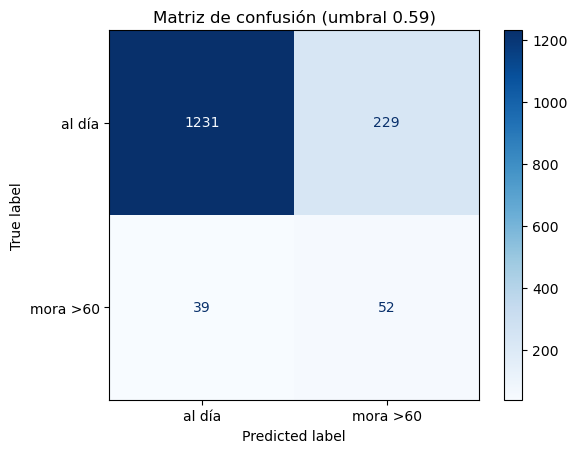

In [10]:
from sklearn.model_selection import cross_val_predict
p_oof = cross_val_predict(Pipeline([("pre", preprocesador), ("modelo", modelos[mejor])]), X_train, y_train,
                          cv=cv, method="predict_proba")[:, 1]          # probabilidades fuera de muestra
CAPACIDAD = 0.20                                                    # fracción de préstamos que cobranzas puede gestionar
UMBRAL = float(np.quantile(p_oof, 1 - CAPACIDAD))
print(f"Umbral elegido (top {CAPACIDAD:.0%} de riesgo): {UMBRAL:.3f}")

pred = (p_test >= UMBRAL).astype(int)
print(classification_report(y_test, pred, target_names=["al día", "mora >60"], digits=3))
print(f"Préstamos marcados: {pred.mean():.1%} | Lift: {y_test[pred == 1].mean() / y_test.mean():.2f}x")
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["al día", "mora >60"]).plot(cmap="Blues")
plt.title(f"Matriz de confusión (umbral {UMBRAL:.2f})"); plt.show()

## 8. ¿Qué variables pesan más? (importancia por permutación sobre test)

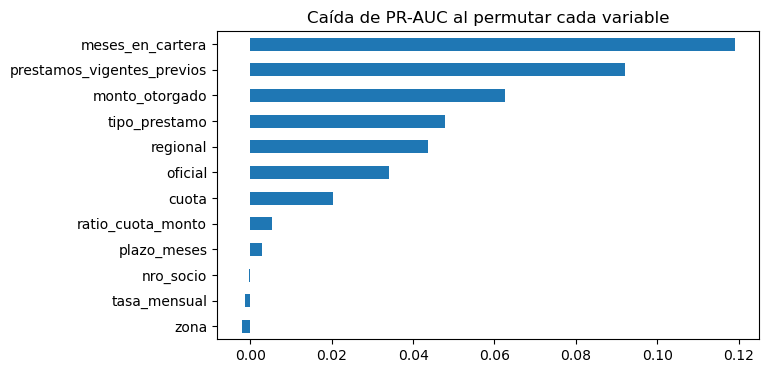

In [11]:
imp = permutation_importance(modelo, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=SEED)
importancia = pd.Series(imp.importances_mean, index=NUM + CAT).sort_values()
importancia.plot.barh(figsize=(7, 4), title="Caída de PR-AUC al permutar cada variable"); plt.show()

## 9. ROI estimado (3 escenarios)

Uso propuesto: **no rechazar préstamos**, sino marcar los de alto riesgo para **gestión de cobranza preventiva** (contacto antes del vencimiento, WhatsApp, ajuste de descuento por planilla).

Supuestos, por mes, con ~1.000 préstamos nuevos:
- Pérdida por cada préstamo que cae en mora >60 días ≈ previsión + costo de gestión ≈ **30% del monto otorgado**.
- La gestión preventiva evita una fracción de las moras detectadas: 10% / 25% / 40% según escenario.
- Costo de gestionar cada préstamo marcado (tiempo de oficial + mensajes): Gs. 30.000 / 20.000 / 15.000.

In [12]:
PRESTAMOS_MES = 1000
escala = PRESTAMOS_MES / len(X_test)
tp = ((pred == 1) & (y_test == 1)).sum() * escala
marcados = (pred == 1).sum() * escala
monto_medio_mora = X_test.loc[y_test == 1, "monto_otorgado"].mean()
escenarios = {"Conservador": (0.10, 30_000), "Base": (0.25, 20_000), "Optimista": (0.40, 15_000)}
filas = []
for nombre, (efectividad, costo_gestion) in escenarios.items():
    ahorro = tp * efectividad * monto_medio_mora * 0.30
    costo = marcados * costo_gestion
    filas.append({"escenario": nombre, "morosos detectados/mes": round(tp), "préstamos gestionados/mes": round(marcados),
                  "ahorro Gs/mes": round(ahorro), "costo Gs/mes": round(costo), "beneficio neto Gs/mes": round(ahorro - costo),
                  "ROI": f"{(ahorro - costo) / costo:.0%}"})
pd.DataFrame(filas).set_index("escenario")

,morosos detectados/mes,préstamos gestionados/mes,ahorro Gs/mes,costo Gs/mes,beneficio neto Gs/mes,ROI
escenario,,,,,,
Conservador,34,181,7799421,5435203,2364218,43%
Base,34,181,19498553,3623469,15875084,438%
Optimista,34,181,31197684,2717602,28480083,1048%


## 9b. Prueba con variables de sueldo (export parcial)

Se obtuvo un export con sueldo, institución y fecha de ingreso de los socios. Se prueba si la relación **cuota / sueldo** mejora el modelo. Solo se ejecuta si el archivo está disponible (no se sube por privacidad).

In [13]:
ARCH_SUELDOS = RAW / "sueldos_pagos.csv"
if ARCH_SUELDOS.exists():
    s = (pd.read_csv(ARCH_SUELDOS, dtype={"cedula": str}, na_values=["NULL"])
           .drop_duplicates("cedula")[["id", "sueldo"]].rename(columns={"id": "nro_socio"}))
    d2 = df.merge(s, on="nro_socio", how="left")
    d2["cuota_sueldo"] = np.where(d2.sueldo > 0, d2.cuota / d2.sueldo, np.nan)
    cubiertos = d2.sueldo.gt(0)
    print(f"Préstamos con sueldo disponible: {cubiertos.sum()} de {len(d2)} ({cubiertos.mean():.1%}), "
          f"morosos entre ellos: {d2.loc[cubiertos, 'mora_60'].sum()}")
    for extra in [[], ["sueldo", "cuota_sueldo"]]:
        pre_x = ColumnTransformer([
            ("num", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                              ("escalar", StandardScaler())]), NUM + extra),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), CAT)])
        r = cross_validate(Pipeline([("pre", pre_x), ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
                           d2[NUM + extra + CAT], d2.mora_60, cv=cv, scoring=["roc_auc", "average_precision"])
        print(f"Variables extra {extra or 'ninguna'}: ROC-AUC {r['test_roc_auc'].mean():.3f} | PR-AUC {r['test_average_precision'].mean():.3f}")
else:
    print("Export de sueldos no disponible; se omite esta prueba.")

Préstamos con sueldo disponible: 193 de 7755 (2.5%), morosos entre ellos: 15
Variables extra ninguna: ROC-AUC 0.792 | PR-AUC 0.252
Variables extra ['sueldo', 'cuota_sueldo']: ROC-AUC 0.791 | PR-AUC 0.251


Variables extra ninguna: ROC-AUC 0.792 | PR-AUC 0.252


Variables extra ['sueldo', 'cuota_sueldo']: ROC-AUC 0.791 | PR-AUC 0.251


**Conclusión:** el export cubre solo ~2,5% de los préstamos (socios con número bajo), con 15 morosos. Con esa cobertura no mejora el modelo, por lo que **no se incorpora**. Exportar el sueldo de toda la cartera es el primer próximo paso.

## 10. Guardar el modelo y probar inferencia

In [14]:
modelo.umbral_ = UMBRAL
modelo.columnas_ = NUM + CAT
joblib.dump(modelo, "model.pkl")

cargado = joblib.load("model.pkl")
nuevo = pd.DataFrame([{
    "monto_otorgado": 10_000_000, "plazo_meses": 24, "tasa_mensual": 2.0, "cuota": 10_000_000 / 24 + 10_000_000 * 0.02,
    "nro_socio": 15000, "prestamos_vigentes_previos": 1, "meses_en_cartera": 12,
    "tipo_prestamo": "EXTRAORDINARIO", "regional": X_train.regional.mode()[0], "zona": X_train.zona.mode()[0],
    "oficial": X_train.oficial.mode()[0],
}])
nuevo["ratio_cuota_monto"] = nuevo.cuota / nuevo.monto_otorgado
prob = cargado.predict_proba(nuevo[cargado.columnas_])[0, 1]
print(f"Score de riesgo (mora >60 días a 12 meses): {prob:.2f} -> {'ALTO RIESGO' if prob >= cargado.umbral_ else 'riesgo normal'}")

Score de riesgo (mora >60 días a 12 meses): 0.82 -> ALTO RIESGO


## 11. Muestra de datos (100 filas, anonimizada)

In [15]:
if archivo == "dataset_mora.csv":
    muestra = pd.concat([df[df.mora_60 == 1].sample(20, random_state=SEED), df[df.mora_60 == 0].sample(80, random_state=SEED)])
    muestra.drop(columns="ratio_cuota_monto").sample(frac=1, random_state=SEED).to_csv("datos_muestra.csv", index=False)
    print("datos_muestra.csv generado (20 morosos + 80 al día, enriquecida en positivos para que el notebook corra con la muestra).")

datos_muestra.csv generado (20 morosos + 80 al día, enriquecida en positivos para que el notebook corra con la muestra).


## 12. Conclusiones y limitaciones

- El modelo usa pesos balanceados por clase, por lo que su salida es un **score de riesgo** para ordenar, no una probabilidad calibrada.
- El modelo ordena el riesgo claramente mejor que el azar (ver PR-AUC vs tasa base) y supera o iguala al baseline logístico.
- Se detectó y corrigió una fuga de datos (regional faltante = socio dado de baja por la propia mora), que inflaba el ROC-AUC de ~0,79 a ~0,84.
- **Limitaciones**: se excluyeron los socios hoy inactivos, lo que subestima la tasa de mora real; el target es una foto al 30/09/2026 y no un resultado a horizonte fijo; el sueldo solo está disponible para ~2,5% de los préstamos y faltan edad, profesión y forma de cobro para toda la cartera; `nro_socio` es solo un proxy de antigüedad.
- **Próximos pasos**: (1) extraer desde la base el historial de cuotas para un target a 12 meses y un split temporal real; (2) sumar datos del padrón de socios y la forma de cobro; (3) integrar el score al flujo de cobranza preventiva por WhatsApp y medir el impacto real.